# 05. Étape 3 : premiers modèles, `fit` / `eval` / `predict`

**Projet AutoML, Challenge Machine Learning (M1 IA, Le Mans Université)**

Ce notebook lance le pipeline complet sur les 6 jeux et montre :

1. les **scores bruts** (accuracy, F1, R²...) de **chaque modèle essayé**, sur la validation ;
2. le **score final** du modèle retenu, sur la validation et sur le test interne ;
3. que `predict` renvoie exactement la forme du fichier `.solution` ;
4. deux visualisations des erreurs : matrice de confusion (`data_D`) et prédiction contre vérité (`data_B`).

**Important : les modèles ne sont pas encore optimisés.** Ils tournent avec leurs réglages par défaut.
Explications détaillées : `docs/STEP3_FIRST_MODELS.md`.

In [1]:
import os, sys, time, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Importer le package automl/ du projet sans l'installer
sys.path.insert(0, os.path.abspath(".."))
DATA = os.path.abspath(os.path.join("..", "dataset"))
JEUX = ["data_A", "data_B", "data_C", "data_D", "data_E", "data_F"]
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.float_format", "{:.4f}".format)

## Paramètres de l'expérience

Le budget réel sera fixé par l'évaluateur via `AUTOML_TIME_BUDGET`. Ici on choisit un budget de test
pour que le notebook s'exécute en quelques minutes ; modifiez-le pour voir l'effet sur les modèles essayés.

In [2]:
os.environ["AUTOML_TIME_BUDGET"] = "120"   # secondes par appel à fit (valeur de test)
os.environ["AUTOML_N_JOBS"] = "4"          # nombre de cœurs autorisés

import automl
from automl.data import load_solution

## 1. Entraînement sur les 6 jeux

In [3]:
resultats = {}
for nom in JEUX:
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):   # masque les messages de fit
        m = automl.AutoML().fit(os.path.join(DATA, nom))
    resultats[nom] = m
    print(f"{nom}: tâche = {m.task.task:18s} modèle retenu = {m.metrics['model']:24s} fit = {time.time() - t0:5.1f} s")

data_A: tâche = multilabel         modèle retenu = hist_gradient_boosting   fit =  18.4 s


data_B: tâche = regression         modèle retenu = hist_gradient_boosting   fit =   2.2 s


data_C: tâche = multiclass_onehot  modèle retenu = hist_gradient_boosting   fit =  70.1 s


data_D: tâche = binary             modèle retenu = random_forest            fit =   1.2 s


data_E: tâche = binary             modèle retenu = hist_gradient_boosting   fit =   1.9 s


data_F: tâche = multiclass_onehot  modèle retenu = linear_svc               fit =   9.3 s


## 2. Scores bruts de chaque modèle essayé (sur la validation)

Pour chaque jeu, un tableau : une ligne par modèle essayé, une colonne par métrique.
Les métriques dépendent de la tâche :

| Tâche | Métriques | Signification |
| :--- | :--- | :--- |
| classification (binaire, multiclasse, one-hot) | `accuracy` | proportion de bonnes réponses |
| | `balanced_accuracy` | accuracy moyenne par classe (utile si une classe est rare) |
| | `f1_macro` | F1 calculé pour chaque classe puis moyenné |
| multi-label | `subset_accuracy` | proportion de lignes dont **tous** les labels sont justes |
| | `label_accuracy` | proportion de labels (0/1) justes |
| | `f1_macro` | F1 de chaque label, moyenné |
| régression | `r2` | 1 = parfait, 0 = aussi mauvais que prédire la moyenne |
| | `rmse`, `mae` | erreur moyenne dans l'unité de la cible (plus bas = mieux) |

Les modèles sont essayés du moins cher au plus cher ; un modèle absent a été sauté faute de temps
(son coût estimé dépassait le budget restant).

In [4]:
for nom, m in resultats.items():
    board = pd.DataFrame(m.leaderboard).set_index("model").drop(columns="score")
    display(Markdown(f"**{nom}** ({m.task.task}) : modèle retenu = `{m.metrics['model']}`"))
    display(board)

**data_A** (multilabel) : modèle retenu = `hist_gradient_boosting`

,durée (s),subset_accuracy,label_accuracy,f1_macro
modèle,,,,
logistic_regression,0.8552,0.6088,0.8541,0.9048
random_forest,5.5972,0.6208,0.8587,0.9089
hist_gradient_boosting,5.1886,0.6349,0.8649,0.9118


**data_B** (regression) : modèle retenu = `hist_gradient_boosting`

,durée (s),r2,rmse,mae
modèle,,,,
ridge,0.0028,0.6305,70228.2077,53839.6786
random_forest,1.2770,0.7476,58041.8849,41217.2615
hist_gradient_boosting,0.6419,0.7991,51781.1948,36269.6263


**data_C** (multiclass_onehot) : modèle retenu = `hist_gradient_boosting`

,durée (s),accuracy,balanced_accuracy,f1_macro
modèle,,,,
logistic_regression,0.8391,0.8861,0.8841,0.8843
random_forest,11.8858,0.9517,0.9515,0.9512
hist_gradient_boosting,53.9659,0.9517,0.9516,0.9514


... (2 outputs left out)

**data_E** (binary) : modèle retenu = `hist_gradient_boosting`

,durée (s),accuracy,balanced_accuracy,f1_macro
modèle,,,,
logistic_regression,0.0089,0.5563,0.5562,0.5561
random_forest,1.0700,0.7389,0.7390,0.7388
hist_gradient_boosting,0.2927,0.8195,0.8193,0.8193


**data_F** (multiclass_onehot) : modèle retenu = `linear_svc`

,durée (s),accuracy,balanced_accuracy,f1_macro
modèle,,,,
linear_svc,0.6228,0.9023,0.8958,0.8965
logistic_regression,7.0991,0.8916,0.8850,0.8857
complement_nb,0.0285,0.8935,0.8844,0.8852


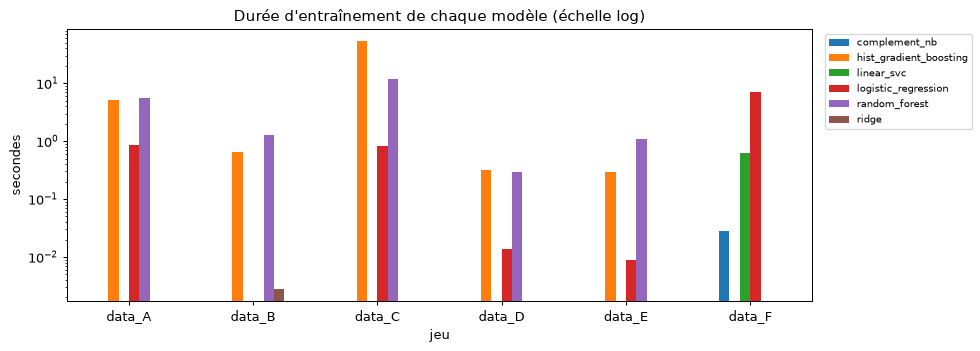

In [5]:
lignes = [{"jeu": nom, "modèle": r["model"], "durée (s)": r["duration_s"]}
          for nom, m in resultats.items() for r in m.leaderboard]
pd.DataFrame(lignes).pivot(index="jeu", columns="modèle", values="durée (s)").plot.bar(
    rot=0, logy=True, figsize=(11, 4), title="Durée d'entraînement de chaque modèle (échelle log)")
plt.ylabel("secondes"); plt.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 3. Score final du modèle retenu

Pour **choisir** entre les modèles, il faut une seule note par modèle. On la calcule à partir des
métriques brutes ci-dessus (`primary_score` dans `automl/metrics.py`) :

| Tâche | Score final |
| :--- | :--- |
| classification | 0,5 x `accuracy` + 0,5 x `f1_macro` |
| multi-label | 0,5 x `f1_macro` + 0,5 x `label_accuracy` |
| régression | `r2` |

Le modèle retenu est celui qui a le meilleur score final sur la **validation**. On le mesure ensuite sur
le **test interne**, qui n'a servi à aucun choix : c'est l'estimation honnête.

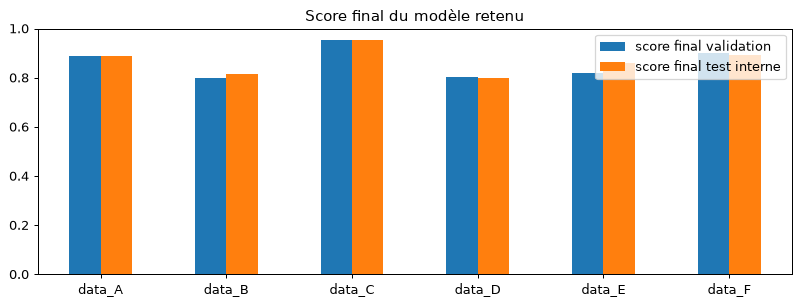

,tâche,modèle retenu,formule,score final validation,score final test interne
data_A,multilabel,hist_gradient_boosting,"0,5 f1_macro + 0,5 label_accuracy",0.8884,0.8882
data_B,regression,hist_gradient_boosting,r2,0.7991,0.8162
data_C,multiclass_onehot,hist_gradient_boosting,"0,5 accuracy + 0,5 f1_macro",0.9515,0.9531
data_D,binary,random_forest,"0,5 accuracy + 0,5 f1_macro",0.8040,0.7968
data_E,binary,hist_gradient_boosting,"0,5 accuracy + 0,5 f1_macro",0.8194,0.8597
data_F,multiclass_onehot,linear_svc,"0,5 accuracy + 0,5 f1_macro",0.8994,0.8924


In [6]:
FORMULE = {"multilabel": "0,5 f1_macro + 0,5 label_accuracy", "regression": "r2",
           "multioutput_regression": "r2 moyen"}
final = pd.DataFrame({nom: {
    "tâche": m.task.task,
    "modèle retenu": m.metrics["model"],
    "formule": FORMULE.get(m.task.task, "0,5 accuracy + 0,5 f1_macro"),
    "score final validation": m.metrics["valid_score"],
    "score final test interne": m.metrics["test_score"],
} for nom, m in resultats.items()}).T
final[["score final validation", "score final test interne"]].astype(float).plot.bar(
    rot=0, figsize=(9, 3.5), ylim=(0, 1), title="Score final du modèle retenu")
plt.tight_layout(); plt.show()
final

### Scores bruts du modèle retenu sur le test interne

In [7]:
for nom, m in resultats.items():
    brut = {k.replace("test_", ""): v for k, v in m.metrics.items() if k.startswith("test_") and k != "test_score"}
    display(Markdown(f"**{nom}** ({m.task.task}), `{m.metrics['model']}`"))
    display(pd.DataFrame([brut], index=["test interne"]))

**data_A** (multilabel), `hist_gradient_boosting`

,subset_accuracy,label_accuracy,f1_macro
test interne,0.6349,0.8649,0.9115


**data_B** (regression), `hist_gradient_boosting`

,r2,rmse,mae
test interne,0.8162,49345.8923,34001.9605


**data_C** (multiclass_onehot), `hist_gradient_boosting`

,accuracy,balanced_accuracy,f1_macro
test interne,0.9533,0.9524,0.9529


... (2 outputs left out)

**data_E** (binary), `hist_gradient_boosting`

,accuracy,balanced_accuracy,f1_macro
test interne,0.8599,0.8596,0.8596


**data_F** (multiclass_onehot), `linear_svc`

,accuracy,balanced_accuracy,f1_macro
test interne,0.8935,0.8895,0.8914


## 4. `predict` respecte le contrat du sujet

On prédit sur chaque dossier (qui contient aussi `.solution`, ici seulement pour comparer les formes).
Le sujet impose : même forme que `.solution`, et en multiclasse one-hot, une matrice one-hot.

In [8]:
lignes = []
for nom, m in resultats.items():
    with contextlib.redirect_stdout(io.StringIO()):
        preds = m.predict(os.path.join(DATA, nom))
    sol = load_solution(os.path.join(DATA, nom, nom + ".solution"))
    onehot_ok = bool(np.all(preds.sum(axis=1) == 1)) if m.task.task == "multiclass_onehot" else None
    lignes.append({"jeu": nom, "forme solution": sol.shape, "forme prédiction": preds.shape,
                   "même forme": preds.shape == sol.shape, "one-hot : lignes qui somment à 1": onehot_ok})
pd.DataFrame(lignes).set_index("jeu")

,forme solution,forme prédiction,même forme,one-hot : lignes qui somment à 1
jeu,,,,
data_A,"(34190, 3)","(34190, 3)",True,None
data_B,"(5000,)","(5000,)",True,None
data_C,"(15000, 10)","(15000, 10)",True,True
data_D,"(2984,)","(2984,)",True,None
data_E,"(3140,)","(3140,)",True,None
data_F,"(13142, 20)","(13142, 20)",True,True


## 5. Visualiser les erreurs sur le test interne

Le modèle final est réentraîné sur train + validation : le test interne n'a toujours jamais été vu.

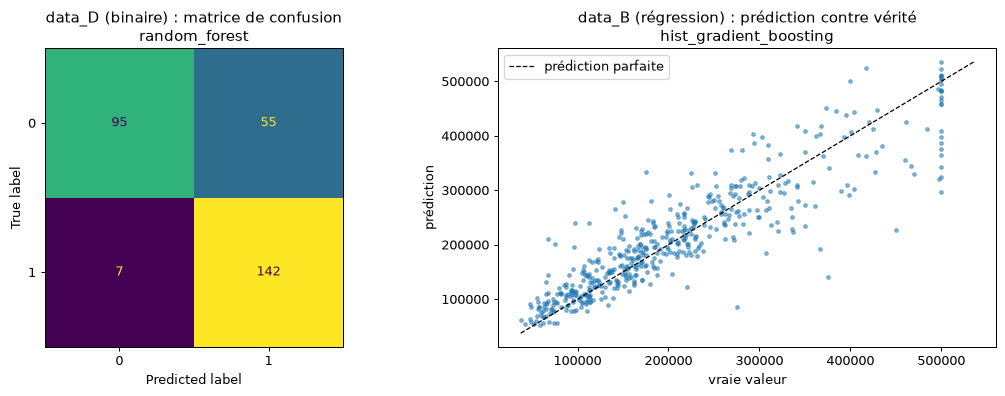

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

m = resultats["data_D"]
X_te, y_te = m.splits["test"]
ConfusionMatrixDisplay.from_predictions(y_te, m.model.predict(X_te), ax=axes[0], colorbar=False)
axes[0].set_title(f"data_D (binaire) : matrice de confusion\n{m.metrics['model']}")

m = resultats["data_B"]
X_te, y_te = m.splits["test"]
pred = m.model.predict(X_te)
axes[1].scatter(y_te, pred, s=8, alpha=0.5)
lim = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
axes[1].plot(lim, lim, "k--", linewidth=1, label="prédiction parfaite")
axes[1].set_xlabel("vraie valeur"); axes[1].set_ylabel("prédiction")
axes[1].set_title(f"data_B (régression) : prédiction contre vérité\n{m.metrics['model']}")
axes[1].legend()
plt.tight_layout(); plt.show()

## Ce qu'il faut retenir, et ce qu'il reste à faire

**Fait :** sur les 6 jeux, `fit` entraîne plusieurs modèles, garde le meilleur, respecte le budget temps,
et `predict` renvoie le format exact attendu.

**Pas encore fait (là où on peut gagner des points) :**

1. **Optimisation des hyperparamètres avec Optuna** : tous les modèles utilisent leurs réglages par défaut.
2. **Ensemble de modèles** : combiner les meilleurs modèles au lieu d'en garder un seul.
3. **Cible asymétrique** (`data_B`) : essayer un modèle sur `log(1 + y)`.
4. **Prétraitement dédié aux arbres** : aujourd'hui, tous les modèles reçoivent les mêmes données standardisées.